# Offensive AI Adaptive Simulator — V6.1 Controlled Autonomous Training

Autonomous synthetic reinforcement-learning simulator with persistent checkpoints, dashboard START/STOP control, live status, automatic dashboard refresh, curriculum learning, and attack-effectiveness analytics.


## 1. Install dependencies


In [ ]:
!pip -q install numpy pandas matplotlib networkx torch tqdm streamlit pyngrok


## 2. Imports and GPU detection


In [ ]:
import os, json, random, time
from collections import deque
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import torch
import torch.nn as nn
import torch.optim as optim

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA:", torch.version.cuda)


Device: cpu


## 3. Persistent checkpoint storage

Google Drive is used when running in Colab. Local storage is only a fallback for testing because a terminated runtime can erase it.


In [ ]:
USE_GOOGLE_DRIVE = True

if USE_GOOGLE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive", force_remount=False)
        CHECKPOINT_DIR = "/content/drive/MyDrive/offensive_ai_v5_checkpoints"
        os.makedirs(CHECKPOINT_DIR, exist_ok=True)
    except Exception as e:
        print("Drive mount unavailable:", e)
        CHECKPOINT_DIR = "/content/offensive_ai_v5_checkpoints"
        os.makedirs(CHECKPOINT_DIR, exist_ok=True)
else:
    CHECKPOINT_DIR = "/content/offensive_ai_v5_checkpoints"
    os.makedirs(CHECKPOINT_DIR, exist_ok=True)

LATEST_PATH = os.path.join(CHECKPOINT_DIR, "latest.pt")
BEST_PATH = os.path.join(CHECKPOINT_DIR, "best.pt")
HISTORY_PATH = os.path.join(CHECKPOINT_DIR, "training_history.csv")
STATUS_PATH = os.path.join(CHECKPOINT_DIR, "training_status.json")
LIVE_EVENT_PATH = os.path.join(CHECKPOINT_DIR, "live_event.json")
ATTACK_STATS_PATH = os.path.join(CHECKPOINT_DIR, "attack_effectiveness.json")
print("Checkpoint directory:", CHECKPOINT_DIR)


Mounted at /content/drive
Checkpoint directory: /content/drive/MyDrive/offensive_ai_v5_checkpoints


## 4. Autonomous training configuration


In [ ]:
CONFIG = {
    # Training continues until the dashboard STOP button is pressed.
    "max_total_episodes": 1_000_000,
    "max_stage_episodes": 1200,
    "eval_every": 50,
    "eval_episodes": 30,
    "mastery_threshold": 0.75,
    "mastery_evals_required": 2,
    "save_every": 25,
    "checkpoint_every_minutes": 10,
    "resume": True,
    "gamma": 0.99,
    "learning_rate": 1e-3,
    "batch_size": 64,
    "replay_capacity": 20000,
    "warmup_steps": 500,
    "target_update_every": 250,
    "epsilon_start": 1.0,
    "epsilon_end": 0.05,
    "epsilon_decay": 0.995,
    "gradient_clip": 5.0,
}
print(json.dumps(CONFIG, indent=2))


{
  "max_total_episodes": 1000000,
  "max_stage_episodes": 1200,
  "eval_every": 50,
  "eval_episodes": 30,
  "mastery_threshold": 0.75,
  "mastery_evals_required": 2,
  "save_every": 25,
  "checkpoint_every_minutes": 10,
  "resume": true,
  "gamma": 0.99,
  "learning_rate": 0.001,
  "batch_size": 64,
  "replay_capacity": 20000,
  "warmup_steps": 500,
  "target_update_every": 250,
  "epsilon_start": 1.0,
  "epsilon_end": 0.05,
  "epsilon_decay": 0.995,
  "gradient_clip": 5.0
}


## 5. Synthetic learning material

The agent does not use RockYou or real password cracking. Credential difficulty is a synthetic variable from 0.20 to 0.92. User vulnerability is generated from synthetic awareness, trust, stress, experience, and fatigue values.


In [ ]:
class SyntheticCredentialModel:
    def __init__(self, seed=42):
        self.rng = random.Random(seed)

    def attempt(self, difficulty, detection_level, attempt_count, scenario):
        base = 0.82 - 0.72 * float(difficulty)
        repetition_penalty = min(0.18, 0.025 * attempt_count)
        detection_penalty = 0.18 * float(detection_level)
        multiplier = float(scenario.get("credential_multiplier", 1.0))
        p = (base - repetition_penalty - detection_penalty) * multiplier
        p = float(np.clip(p, 0.03, 0.90))
        return self.rng.random() < p, p

class SyntheticUserProfile:
    def __init__(self, awareness, trust, stress, experience, fatigue):
        self.awareness = float(awareness)
        self.trust = float(trust)
        self.stress = float(stress)
        self.experience = float(experience)
        self.fatigue = float(fatigue)

    def vulnerability(self, stress_multiplier=1.0, fatigue_multiplier=1.0):
        stress = np.clip(self.stress * stress_multiplier, 0, 1)
        fatigue = np.clip(self.fatigue * fatigue_multiplier, 0, 1)
        score = ((1-self.awareness) * 0.30 +
                  self.trust * 0.25 +
                  stress * 0.20 +
                  (1-self.experience) * 0.15 +
                  fatigue * 0.10)
        return float(np.clip(score, 0, 1))


## 6. Synthetic enterprise environment


In [ ]:
class SyntheticEnterpriseEnv:
    ACTIONS = ["Credential Attack", "Social Engineering",
               "Privilege Escalation", "Lateral Movement"]
    PRIVILEGE_LEVELS = {"user":1, "admin":2, "server":3, "critical":4}

    def __init__(self, scenario=None, seed=42):
        self.scenario = scenario or {}
        self.rng = random.Random(seed)
        self.nodes = ["john","alice","raj","sara","analyst","admin","database","domain_controller"]
        self.privileges = {
            "john":"user","alice":"user","raj":"user","sara":"user",
            "analyst":"admin","admin":"admin","database":"server",
            "domain_controller":"critical"
        }
        self.edges = [
            ("john","admin"),("alice","admin"),("raj","admin"),("sara","admin"),
            ("analyst","domain_controller"),("admin","database"),
            ("database","domain_controller")
        ]
        self.trust = {
            "john":["raj","admin"],"alice":["admin"],"raj":["john","admin"],
            "sara":["admin"],"analyst":["domain_controller"],
            "admin":["database"],"database":["domain_controller"]
        }
        self.credential_difficulty = {
            "john":0.20,"alice":0.35,"raj":0.45,"sara":0.50,
            "analyst":0.70,"admin":0.78,"database":0.86,
            "domain_controller":0.92
        }
        self.profiles = {
            "john":SyntheticUserProfile(.45,.75,.60,.45,.55),
            "alice":SyntheticUserProfile(.65,.55,.40,.65,.35),
            "raj":SyntheticUserProfile(.50,.80,.55,.50,.60),
            "sara":SyntheticUserProfile(.72,.50,.35,.70,.30),
            "analyst":SyntheticUserProfile(.85,.25,.30,.90,.20),
            "admin":SyntheticUserProfile(.88,.20,.25,.95,.15),
            "database":SyntheticUserProfile(.90,.10,.15,.98,.10),
            "domain_controller":SyntheticUserProfile(.95,.05,.10,1.0,.05)
        }
        self.graph = nx.Graph()
        self.graph.add_nodes_from(self.nodes)
        self.graph.add_edges_from(self.edges)
        self.credential_model = SyntheticCredentialModel(seed+11)
        self.reset()

    @property
    def state_size(self):
        return len(self.nodes)*7 + len(self.nodes) + 4

    @property
    def action_size(self):
        return len(self.ACTIONS)

    def reset(self):
        self.compromised = {n:False for n in self.nodes}
        self.attack_count = {n:0 for n in self.nodes}
        self.success_count = {n:0 for n in self.nodes}
        self.current_node = self.scenario.get("start_node", self.rng.choice(self.nodes))
        for n in self.scenario.get("initial_compromised_nodes", []):
            if n in self.compromised:
                self.compromised[n] = True
        self.node_privileges = dict(self.privileges)
        self.steps = 0
        self.reward_total = 0.0
        self.detected_events = 0
        self.detection_level = float(self.scenario.get("initial_detection", 0.05))
        self.alert_level = 0.0
        self.attack_budget = int(self.scenario.get("attack_budget", 30))
        return self.get_state()

    def trust_score(self, source, target):
        base = 0.20
        if target in self.trust.get(source, []):
            base = 0.85
        elif source in self.trust.get(target, []):
            base = 0.60
        return float(np.clip(base*float(self.scenario.get("trust_multiplier",1.0)),0.05,0.95))

    def vulnerability(self, node):
        return self.profiles[node].vulnerability(
            self.scenario.get("stress_multiplier",1.0),
            self.scenario.get("fatigue_multiplier",1.0)
        )

    def valid_action_mask(self):
        node = self.current_node
        compromised = self.compromised[node]
        privilege = self.PRIVILEGE_LEVELS[self.node_privileges[node]]
        unvisited = any(not self.compromised[n] for n in self.graph.neighbors(node))
        return np.asarray([
            not compromised,
            not compromised,
            compromised and privilege < 4,
            compromised and unvisited
        ], dtype=bool)

    def get_state(self):
        state = []
        max_degree = max(dict(self.graph.degree()).values())
        for node in self.nodes:
            p = self.PRIVILEGE_LEVELS[self.node_privileges[node]]
            attempts = min(self.attack_count[node]/10.0,1.0)
            success_rate = self.success_count[node]/self.attack_count[node] if self.attack_count[node] else 0.0
            neighbors = list(self.graph.neighbors(node))
            neighbor_comp = sum(self.compromised[n] for n in neighbors)/len(neighbors) if neighbors else 0.0
            degree = self.graph.degree(node)/max_degree
            state.extend([
                float(self.compromised[node]), p/4.0, degree,
                self.vulnerability(node), attempts, success_rate, neighbor_comp
            ])
        state.extend([float(n == self.current_node) for n in self.nodes])
        state.extend([
            np.clip(self.detection_level,0,1),
            np.clip(self.alert_level,0,1),
            np.clip(self.attack_budget/max(1,int(self.scenario.get("attack_budget",30))),0,1),
            np.clip(sum(self.compromised.values())/len(self.nodes),0,1)
        ])
        return np.asarray(state,dtype=np.float32)

    def goal_reached(self):
        mode = self.scenario.get("goal_mode","domain_controller")
        if mode == "current_compromised":
            return self.compromised[self.current_node]
        if mode == "node_compromised":
            node = self.scenario.get("goal_node")
            return bool(node and self.compromised[node])
        if mode == "compromised_count":
            return sum(self.compromised.values()) >= int(self.scenario.get("goal_count",2))
        if mode == "privilege":
            node = self.scenario.get("goal_node",self.current_node)
            return self.PRIVILEGE_LEVELS[self.node_privileges[node]] >= int(self.scenario.get("goal_privilege",2))
        return self.compromised["domain_controller"]

    def detection_probability(self, action, success):
        base = float(self.scenario.get("base_detection",0.10))
        factor = {
            "Credential Attack":0.14,
            "Social Engineering":0.10,
            "Privilege Escalation":0.22,
            "Lateral Movement":0.18
        }[action]
        p = base + factor + 0.35*self.detection_level + 0.10*self.alert_level
        p += 0.025*min(self.attack_count[self.current_node],6)
        if success:
            p += 0.04
        p -= float(self.scenario.get("stealth_bonus",0.0))
        return float(np.clip(p,0.02,0.95))

    def step(self, action):
        action = int(action)
        mask = self.valid_action_mask()
        if action < 0 or action >= self.action_size or not mask[action]:
            raise ValueError("Invalid action for current state")

        node = self.current_node
        old_comp = sum(self.compromised.values())
        old_priv = self.PRIVILEGE_LEVELS[self.node_privileges[node]]
        self.steps += 1
        self.attack_budget -= 1
        self.attack_count[node] += 1
        success, target = False, None
        details = {}

        if action == 0:
            success, p = self.credential_model.attempt(
                self.credential_difficulty[node],
                self.detection_level,
                self.attack_count[node],
                self.scenario
            )
            details["probability"] = p
            reward = 4.0 if success else -1.0

        elif action == 1:
            p = self.vulnerability(node) * float(self.scenario.get("social_multiplier",1.0))
            p = float(np.clip(p,0.03,0.90))
            success = self.rng.random() < p
            details["probability"] = p
            reward = 5.0 if success else -1.0

        elif action == 2:
            neighbors = list(self.graph.neighbors(node))
            pressure = np.mean([self.compromised[n] for n in neighbors]) if neighbors else 0.0
            p = (0.18 + 0.20*pressure + 0.08*(4-old_priv))
            p *= float(self.scenario.get("privilege_multiplier",1.0))
            p = float(np.clip(p,0.02,0.90))
            success = self.rng.random() < p
            details["probability"] = p
            if success:
                self.node_privileges[node] = {1:"admin",2:"server",3:"critical"}.get(old_priv,"critical")
                self.success_count[node] += 1
            reward = 7.0 if success else -1.0

        else:
            candidates = [n for n in self.graph.neighbors(node) if not self.compromised[n]]
            target = max(candidates,key=lambda n:self.trust_score(node,n)) if candidates else None
            p = (0.20 + 0.60*self.trust_score(node,target)) if target else 0.0
            p *= float(self.scenario.get("lateral_multiplier",1.0))
            p = float(np.clip(p,0.02,0.92))
            success = self.rng.random() < p
            details["probability"] = p
            details["target"] = target
            if success and target:
                self.compromised[target] = True
                self.success_count[target] += 1
                self.current_node = target
            reward = 8.0 if success else -1.0

        if action in (0,1) and success:
            self.compromised[node] = True
            self.success_count[node] += 1

        new_comp = sum(self.compromised.values())
        new_priv = self.PRIVILEGE_LEVELS[self.node_privileges[node]]
        if new_comp > old_comp:
            reward += 8.0*(new_comp-old_comp)
        if new_priv > old_priv:
            reward += 5.0*(new_priv-old_priv)

        dp = self.detection_probability(self.ACTIONS[action],success)
        detected = self.rng.random() < dp
        self.detection_level = float(np.clip(
            0.96*self.detection_level + 0.20*dp + (0.03 if success else 0),0,1
        ))

        if detected:
            self.detected_events += 1
            self.alert_level = float(np.clip(self.alert_level+0.22+0.08*dp,0,1))
            reward -= float(self.scenario.get("detection_penalty",4.0))
        else:
            self.alert_level *= float(self.scenario.get("alert_decay",0.96))

        goal = self.goal_reached()
        if goal:
            reward += float(self.scenario.get("goal_reward",50.0))

        contained = self.alert_level >= float(self.scenario.get("containment_threshold",0.95))
        if contained:
            reward -= float(self.scenario.get("containment_penalty",10.0))

        self.reward_total += reward
        done = bool(goal or contained or self.attack_budget <= 0 or not self.valid_action_mask().any())

        info = {
            "action":self.ACTIONS[action],"node":node,"target":target,
            "success":bool(success),"detected":bool(detected),
            "detection_probability":float(dp),"goal_reached":bool(goal),
            "contained":bool(contained),"reward":float(reward),
            "detection_level":float(self.detection_level),
            "alert_level":float(self.alert_level),
            "attack_budget":int(self.attack_budget),**details
        }
        return self.get_state(),float(reward),done,info


## 7. Curriculum


In [ ]:
CURRICULUM = [
    {"name":"Stage 1 — Basic Compromise","base_detection":0.05,"initial_detection":0.03,"attack_budget":20,"credential_multiplier":1.10,"social_multiplier":1.15,"trust_multiplier":1.05,"stealth_bonus":0.03,"goal_mode":"current_compromised","goal_reward":40},
    {"name":"Stage 2 — Detection Awareness","base_detection":0.15,"initial_detection":0.10,"attack_budget":24,"credential_multiplier":1.05,"social_multiplier":1.05,"goal_mode":"current_compromised","goal_reward":45},
    {"name":"Stage 3 — Privilege Escalation","base_detection":0.12,"initial_detection":0.08,"attack_budget":28,"privilege_multiplier":1.15,"goal_mode":"privilege","goal_node":"admin","goal_privilege":3,"goal_reward":55},
    {"name":"Stage 4 — Lateral Movement","base_detection":0.15,"initial_detection":0.10,"attack_budget":30,"trust_multiplier":1.15,"lateral_multiplier":1.05,"goal_mode":"compromised_count","goal_count":3,"goal_reward":60},
    {"name":"Stage 5 — High Detection","base_detection":0.30,"initial_detection":0.25,"attack_budget":30,"trust_multiplier":1.05,"detection_penalty":5.0,"stealth_bonus":0.04,"goal_mode":"compromised_count","goal_count":3,"goal_reward":65},
    {"name":"Stage 6 — Low Trust","base_detection":0.20,"initial_detection":0.15,"attack_budget":32,"trust_multiplier":0.65,"lateral_multiplier":0.80,"goal_mode":"compromised_count","goal_count":3,"goal_reward":70},
    {"name":"Stage 7 — Stressed Users","base_detection":0.18,"initial_detection":0.12,"attack_budget":32,"stress_multiplier":1.45,"fatigue_multiplier":1.40,"social_multiplier":1.15,"goal_mode":"compromised_count","goal_count":4,"goal_reward":75},
    {"name":"Stage 8 — Full Adaptive Scenario","base_detection":0.24,"initial_detection":0.20,"attack_budget":35,"trust_multiplier":0.90,"stress_multiplier":1.25,"fatigue_multiplier":1.25,"credential_multiplier":0.90,"social_multiplier":1.05,"privilege_multiplier":0.95,"lateral_multiplier":0.90,"detection_penalty":5.0,"stealth_bonus":0.03,"goal_mode":"domain_controller","goal_reward":100}
]
for i,s in enumerate(CURRICULUM,1):
    print(i,s["name"])


1 Stage 1 — Basic Compromise
2 Stage 2 — Detection Awareness
3 Stage 3 — Privilege Escalation
4 Stage 4 — Lateral Movement
5 Stage 5 — High Detection
6 Stage 6 — Low Trust
7 Stage 7 — Stressed Users
8 Stage 8 — Full Adaptive Scenario


## 8. Double DQN agent


In [ ]:
class ReplayBuffer:
    def __init__(self,capacity):
        self.buffer = deque(maxlen=capacity)
    def add(self,state,action,reward,next_state,done,next_mask):
        self.buffer.append((np.asarray(state,np.float32),int(action),float(reward),
                           np.asarray(next_state,np.float32),bool(done),np.asarray(next_mask,bool)))
    def sample(self,n):
        b=random.sample(self.buffer,n)
        s,a,r,ns,d,m=zip(*b)
        return np.asarray(s,np.float32),np.asarray(a,np.int64),np.asarray(r,np.float32),np.asarray(ns,np.float32),np.asarray(d,np.float32),np.asarray(m,bool)
    def __len__(self):
        return len(self.buffer)

class QNetwork(nn.Module):
    def __init__(self,state_size,action_size):
        super().__init__()
        self.net=nn.Sequential(
            nn.Linear(state_size,256),nn.ReLU(),
            nn.Linear(256,128),nn.ReLU(),
            nn.Linear(128,64),nn.ReLU(),
            nn.Linear(64,action_size)
        )
    def forward(self,x):
        return self.net(x)

class DoubleDQNAgent:
    def __init__(self,state_size,action_size):
        self.policy=QNetwork(state_size,action_size).to(DEVICE)
        self.target=QNetwork(state_size,action_size).to(DEVICE)
        self.target.load_state_dict(self.policy.state_dict())
        self.target.eval()
        self.optimizer=optim.Adam(self.policy.parameters(),lr=CONFIG["learning_rate"])
        self.loss_fn=nn.SmoothL1Loss()
        self.memory=ReplayBuffer(CONFIG["replay_capacity"])
        self.gamma=CONFIG["gamma"]
        self.epsilon=CONFIG["epsilon_start"]
        self.learn_steps=0
        self.steps=0

    def act(self,state,mask,training=True):
        valid=np.flatnonzero(mask)
        if len(valid)==0:
            return 0
        if training and random.random()<self.epsilon:
            return int(random.choice(valid.tolist()))
        with torch.no_grad():
            x=torch.tensor(state,dtype=torch.float32,device=DEVICE).unsqueeze(0)
            q=self.policy(x).squeeze(0).cpu().numpy()
        q[~mask]=-np.inf
        return int(np.argmax(q))

    def remember(self,*args):
        self.memory.add(*args)

    def learn(self):
        if len(self.memory)<max(CONFIG["batch_size"],CONFIG["warmup_steps"]):
            return None
        states,actions,rewards,next_states,dones,masks=self.memory.sample(CONFIG["batch_size"])
        s=torch.tensor(states,dtype=torch.float32,device=DEVICE)
        a=torch.tensor(actions,dtype=torch.long,device=DEVICE)
        r=torch.tensor(rewards,dtype=torch.float32,device=DEVICE)
        ns=torch.tensor(next_states,dtype=torch.float32,device=DEVICE)
        d=torch.tensor(dones,dtype=torch.float32,device=DEVICE)

        current=self.policy(s).gather(1,a.unsqueeze(1)).squeeze(1)
        with torch.no_grad():
            q_next=self.policy(ns)
            mask_t=torch.tensor(masks,dtype=torch.bool,device=DEVICE)
            q_next[~mask_t]=-torch.inf
            next_a=q_next.argmax(1,keepdim=True)
            next_q=self.target(ns).gather(1,next_a).squeeze(1)
            target=r+self.gamma*next_q*(1-d)

        loss=self.loss_fn(current,target)
        self.optimizer.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(self.policy.parameters(),CONFIG["gradient_clip"])
        self.optimizer.step()
        self.learn_steps+=1
        if self.learn_steps%CONFIG["target_update_every"]==0:
            self.target.load_state_dict(self.policy.state_dict())
        return float(loss.item())

    def decay_epsilon(self):
        self.epsilon=max(CONFIG["epsilon_end"],self.epsilon*CONFIG["epsilon_decay"])

    def state_dict(self):
        return {"policy":self.policy.state_dict(),"target":self.target.state_dict(),
                "optimizer":self.optimizer.state_dict(),"epsilon":self.epsilon,
                "learn_steps":self.learn_steps,"steps":self.steps}

    def load_state_dict(self,d):
        self.policy.load_state_dict(d["policy"])
        self.target.load_state_dict(d["target"])
        self.optimizer.load_state_dict(d["optimizer"])
        self.epsilon=float(d["epsilon"])
        self.learn_steps=int(d["learn_steps"])
        self.steps=int(d["steps"])


## 9. Checkpointing


In [ ]:
def save_checkpoint(agent,state,path=LATEST_PATH):
    payload={"agent":agent.state_dict(),"training_state":state,
             "saved_at":datetime.now(timezone.utc).isoformat()}
    tmp=path+".tmp"
    torch.save(payload,tmp)
    os.replace(tmp,path)

def load_checkpoint(agent,path=LATEST_PATH):
    if not os.path.exists(path):
        return None
    data=torch.load(path,map_location=DEVICE,weights_only=False)
    agent.load_state_dict(data["agent"])
    return data["training_state"]

def write_status(state):
    tmp=STATUS_PATH+".tmp"
    with open(tmp,"w") as f:
        json.dump(state,f,indent=2,default=str)
    os.replace(tmp,STATUS_PATH)

def append_history(row):
    df=pd.DataFrame([row])
    df.to_csv(HISTORY_PATH,mode="a",header=not os.path.exists(HISTORY_PATH),index=False)

CONTROL_PATH = os.path.join(CHECKPOINT_DIR, "training_control.json")

def read_training_command():
    try:
        with open(CONTROL_PATH, "r") as f:
            return json.load(f).get("command", "idle").lower()
    except Exception:
        return "idle"

def write_training_command(command):
    payload = {
        "command": command,
        "timestamp": datetime.now(timezone.utc).isoformat(),
    }
    tmp = CONTROL_PATH + ".tmp"
    with open(tmp, "w") as f:
        json.dump(payload, f, indent=2)
    os.replace(tmp, CONTROL_PATH)

def request_start():
    write_training_command("start")

def request_stop():
    write_training_command("stop")

if not os.path.exists(CONTROL_PATH):
    write_training_command("idle")


In [ ]:
def write_live_event(event):
    payload = {**event, "timestamp": datetime.now(timezone.utc).isoformat()}
    tmp = LIVE_EVENT_PATH + ".tmp"
    with open(tmp, "w") as f:
        json.dump(payload, f, indent=2, default=str)
    os.replace(tmp, LIVE_EVENT_PATH)


In [ ]:
def write_attack_stats(stats):
    tmp = ATTACK_STATS_PATH + ".tmp"
    with open(tmp, "w") as f:
        json.dump(stats, f, indent=2, default=str)
    os.replace(tmp, ATTACK_STATS_PATH)


## 10. Evaluation


In [ ]:
# ============================================================
# INTERRUPTIBLE EVALUATION FUNCTION
# ============================================================

def evaluate_agent(agent, scenario, episodes=30, seed_offset=10000):
    """
    Evaluate the agent while remaining responsive to the
    Streamlit START/STOP control.

    If STOP is requested:
      - evaluation stops immediately
      - partial evaluation results are discarded
      - the autonomous trainer handles checkpointing
    """

    goals = []
    rewards = []
    detections = []
    lengths = []

    for ep in range(episodes):

        # ----------------------------------------------------
        # Check dashboard STOP before starting an episode
        # ----------------------------------------------------
        if read_training_command() == "stop":
            print("STOP requested during evaluation.")
            break

        env = SyntheticEnterpriseEnv(
            scenario,
            seed_offset + ep
        )

        state = env.reset()
        total = 0.0
        detected = 0

        # ----------------------------------------------------
        # Evaluation episode
        # ----------------------------------------------------
        for _ in range(
            int(scenario.get("attack_budget", 30))
        ):

            # Check STOP during evaluation
            if read_training_command() == "stop":
                print("STOP requested during evaluation.")
                break

            mask = env.valid_action_mask()

            if not mask.any():
                break

            action = agent.act(
                state,
                mask,
                training=False
            )

            ns, reward, done, info = env.step(action)

            state = ns
            total += reward
            detected += int(
                info.get("detected", False)
            )

            if done:
                break

        # ----------------------------------------------------
        # If STOP was requested during this episode,
        # don't count the incomplete evaluation episode.
        # ----------------------------------------------------
        if read_training_command() == "stop":
            print("Evaluation interrupted by STOP command.")
            break

        # ----------------------------------------------------
        # Store completed evaluation episode
        # ----------------------------------------------------
        goals.append(
            int(env.goal_reached())
        )

        rewards.append(
            float(total)
        )

        detections.append(
            detected / max(1, env.steps)
        )

        lengths.append(
            env.steps
        )

    # ========================================================
    # Return safe metrics
    # ========================================================

    if not goals:
        return {
            "goal_rate": 0.0,
            "mean_reward": 0.0,
            "detection_rate": 0.0,
            "mean_episode_length": 0.0
        }

    return {
        "goal_rate": float(
            np.mean(goals)
        ),

        "mean_reward": float(
            np.mean(rewards)
        ),

        "detection_rate": float(
            np.mean(detections)
        ),

        "mean_episode_length": float(
            np.mean(lengths)
        )
    }


print("Interruptible evaluation function loaded.")
print("STOP requests will now be detected during evaluation.")

Interruptible evaluation function loaded.
STOP requests will now be detected during evaluation.


## 11. Autonomous trainer


### V6.1 stability fixes

The trainer is controlled by the Streamlit dashboard and no longer calls the removed notebook-only live renderer. Evaluation loads the latest checkpoint directly, so it can run while the autonomous worker is in the background. The dashboard refreshes automatically every 3 seconds.


In [ ]:
def _autonomous_train_impl():
    probe=SyntheticEnterpriseEnv(CURRICULUM[0],SEED)
    agent=DoubleDQNAgent(probe.state_size,probe.action_size)

    state={
        "episode":0,"stage_index":0,"stage_episode":0,
        "mastery_count":0,"best_goal_rate":0.0,
        "best_stage_goal_rate":0.0,"last_eval":{},
        "started_at":None
    }

    action_names = SyntheticEnterpriseEnv.ACTIONS
    state["attack_stats"] = {
        name: {"attempts":0,"successes":0,"detections":0,
               "total_reward":0.0,"goal_contributions":0}
        for name in action_names
    }

    if CONFIG["resume"] and os.path.exists(LATEST_PATH):
        restored=load_checkpoint(agent)
        if restored:
            state.update(restored)
            print("Resumed from episode",state["episode"],"stage",state["stage_index"]+1)

    # Never discard persisted attack statistics when resuming.
    if not state.get("attack_stats"):
        state["attack_stats"] = {
            name: {"attempts":0,"successes":0,"detections":0,
                   "total_reward":0.0,"goal_contributions":0}
            for name in action_names
        }

    last_save=time.time()
    started_at=None

    write_status({
        **state,
        "state":"idle",
        "current_stage":CURRICULUM[min(state["stage_index"],len(CURRICULUM)-1)]["name"],
        "device":str(DEVICE),
        "checkpoint":LATEST_PATH,
        "last_heartbeat":time.time(),
        "message":"Waiting for START from dashboard"
    })

    while True:
        # Dashboard controls the worker through a persistent command file.
        command=read_training_command()
        if command == "stop":
            save_checkpoint(agent,state)
            write_attack_stats(state["attack_stats"])
            write_status({
                **state,"state":"stopped","device":str(DEVICE),
                "checkpoint":LATEST_PATH,"last_heartbeat":time.time(),
                "stopped_at":datetime.now(timezone.utc).isoformat(),
                "message":"Training stopped by dashboard; worker remains ready for START"
            })
            write_training_command("idle")
            started_at=None
            time.sleep(1)
            continue

        if command != "start":
            write_status({
                **state,"state":"idle","device":str(DEVICE),
                "checkpoint":LATEST_PATH,"last_heartbeat":time.time(),
                "message":"Waiting for START from dashboard"
            })
            time.sleep(1)
            continue

        if started_at is None:
            started_at=datetime.now(timezone.utc).isoformat()
            state["started_at"]=started_at
            write_status({
                **state,"state":"running","device":str(DEVICE),
                "checkpoint":LATEST_PATH,"last_heartbeat":time.time(),
                "started_at":started_at
            })

        # Effectively unlimited training. STOP is the normal termination mechanism.
        if state["episode"] >= CONFIG["max_total_episodes"]:
            state["episode"]=0
            state["stage_episode"]=0

        stage=state["stage_index"]
        if stage>=len(CURRICULUM):
            stage=len(CURRICULUM)-1
            state["stage_index"]=stage

        scenario=CURRICULUM[stage]

        # Advance stages when their episode budget is exhausted. On the final
        # stage, roll the stage counter over and keep training instead of ending.
        if state["stage_episode"]>=CONFIG["max_stage_episodes"]:
            if stage<len(CURRICULUM)-1:
                state["stage_index"]+=1
                state["stage_episode"]=0
                state["mastery_count"]=0
                state["best_stage_goal_rate"]=0.0
                continue
            state["stage_episode"]=0

        env=SyntheticEnterpriseEnv(scenario,SEED+state["episode"]*17)
        obs=env.reset()
        episode_reward=0.0
        losses=[]
        info={}

        for _ in range(int(scenario.get("attack_budget",30))):
            if read_training_command()=="stop":
                break
            mask=env.valid_action_mask()
            if not mask.any(): break

            action=agent.act(obs,mask,training=True)
            nxt,reward,done,info=env.step(action)
            action_name=info["action"]
            stats=state["attack_stats"].setdefault(action_name,{"attempts":0,"successes":0,"detections":0,"total_reward":0.0,"goal_contributions":0})
            stats["attempts"]+=1
            stats["successes"]+=int(info.get("success",False))
            stats["detections"]+=int(info.get("detected",False))
            stats["total_reward"]+=float(reward)
            stats["goal_contributions"]+=int(info.get("goal_reached",False))

            next_mask=env.valid_action_mask()
            agent.remember(obs,action,reward,nxt,done,next_mask)
            loss=agent.learn()
            if loss is not None: losses.append(loss)
            obs=nxt
            episode_reward+=reward
            if done: break

        # If STOP was pressed during the episode, checkpoint without counting a partial episode.
        if read_training_command()=="stop":
            save_checkpoint(agent,state)
            write_attack_stats(state["attack_stats"])
            write_status({
                **state,"state":"stopped","device":str(DEVICE),
                "checkpoint":LATEST_PATH,"last_heartbeat":time.time(),
                "stopped_at":datetime.now(timezone.utc).isoformat(),
                "message":"Training stopped by dashboard; worker remains ready for START"
            })
            write_training_command("idle")
            started_at=None
            time.sleep(1)
            continue

        agent.steps+=1
        agent.decay_epsilon()
        state["episode"]+=1
        state["stage_episode"]+=1
        ep=state["episode"]

        append_history({
            "episode":ep,"stage":stage+1,"stage_name":scenario["name"],
            "episode_reward":episode_reward,
            "goal_reached":int(env.goal_reached()),
            "detected_events":env.detected_events,"steps":env.steps,
            "epsilon":agent.epsilon,
            "loss":float(np.mean(losses)) if losses else np.nan,
            "timestamp":datetime.now(timezone.utc).isoformat()
        })
        write_attack_stats(state["attack_stats"])
        write_live_event({
            "episode":ep,"stage":stage+1,"stage_name":scenario["name"],
            "episode_reward":float(episode_reward),"goal_reached":bool(env.goal_reached()),
            "detected_events":int(env.detected_events),"steps":int(env.steps),
            "epsilon":float(agent.epsilon),
            "last_action":info.get("action"),"last_node":info.get("node"),"last_target":info.get("target"),
            "last_success":bool(info.get("success",False)),"last_detected":bool(info.get("detected",False)),
            "detection_level":float(env.detection_level),"alert_level":float(env.alert_level),
            "attack_budget_remaining":int(env.attack_budget),"device":str(DEVICE)
        })

        if ep%CONFIG["eval_every"]==0:
            metrics=evaluate_agent(agent,scenario,CONFIG["eval_episodes"],100000+ep)
            state["last_eval"]=metrics
            goal=metrics["goal_rate"]
            state["best_goal_rate"]=max(state["best_goal_rate"],goal)
            if goal>state["best_stage_goal_rate"]:
                state["best_stage_goal_rate"]=goal
                save_checkpoint(agent,state,BEST_PATH)
            if goal>=CONFIG["mastery_threshold"]:
                state["mastery_count"]+=1
            else:
                state["mastery_count"]=0
            print(f"Episode {ep} | Stage {stage+1}/{len(CURRICULUM)} | Goal {goal:.1%} | Reward {metrics['mean_reward']:.2f} | Detection {metrics['detection_rate']:.1%} | Epsilon {agent.epsilon:.3f}")
            # Streamlit is the live dashboard; no notebook renderer is required here.
            if state["mastery_count"]>=CONFIG["mastery_evals_required"]:
                print("MASTERED:",scenario["name"])
                if stage<len(CURRICULUM)-1:
                    state["stage_index"]+=1
                    state["stage_episode"]=0
                    state["mastery_count"]=0
                    state["best_stage_goal_rate"]=0.0
                else:
                    # Final-stage mastery is a milestone, not a reason to stop.
                    state["mastery_count"]=0
                    print("Final curriculum mastered; continuing adaptive training until STOP.")

        write_status({
            **state,"state":"running",
            "current_stage":CURRICULUM[min(state["stage_index"],len(CURRICULUM)-1)]["name"],
            "device":str(DEVICE),"checkpoint":LATEST_PATH,
            "last_heartbeat":time.time(),
            "last_episode_completed_at":datetime.now(timezone.utc).isoformat(),
            "message":"Training continuously until STOP"
        })

        if ep%CONFIG["save_every"]==0 or time.time()-last_save>=CONFIG["checkpoint_every_minutes"]*60:
            save_checkpoint(agent,state)
            write_attack_stats(state["attack_stats"])
            last_save=time.time()


def autonomous_train():
    try:
        return _autonomous_train_impl()
    except Exception as exc:
        try:
            write_status({"state":"error","error":str(exc),"error_type":type(exc).__name__,"last_heartbeat":time.time(),"failed_at":datetime.now(timezone.utc).isoformat()})
        except Exception:
            pass
        raise


## 12. START AUTONOMOUS WORKER

Run this cell once. It starts a background worker that waits for the Streamlit dashboard's START button. START resumes training from the latest checkpoint; STOP requests a graceful checkpoint and returns the worker to IDLE, ready for the next START.


In [ ]:
# Start the autonomous worker once. It waits in IDLE until START is pressed in Streamlit.
import threading
import traceback

TRAINING_THREAD = None
TRAINING_ERROR = None

def _run_autonomous_training():
    global agent, training_state, TRAINING_ERROR
    try:
        agent, training_state = autonomous_train()
    except Exception:
        TRAINING_ERROR = traceback.format_exc()
        print(TRAINING_ERROR)

if TRAINING_THREAD is None or not TRAINING_THREAD.is_alive():
    TRAINING_THREAD = threading.Thread(
        target=_run_autonomous_training,
        name="autonomous-training",
        daemon=True
    )
    TRAINING_THREAD.start()
    print("Autonomous worker started and is waiting for START from the dashboard.")
else:
    print("Autonomous worker is already running.")


Autonomous worker started and is waiting for START from the dashboard.


## 13. Training curves


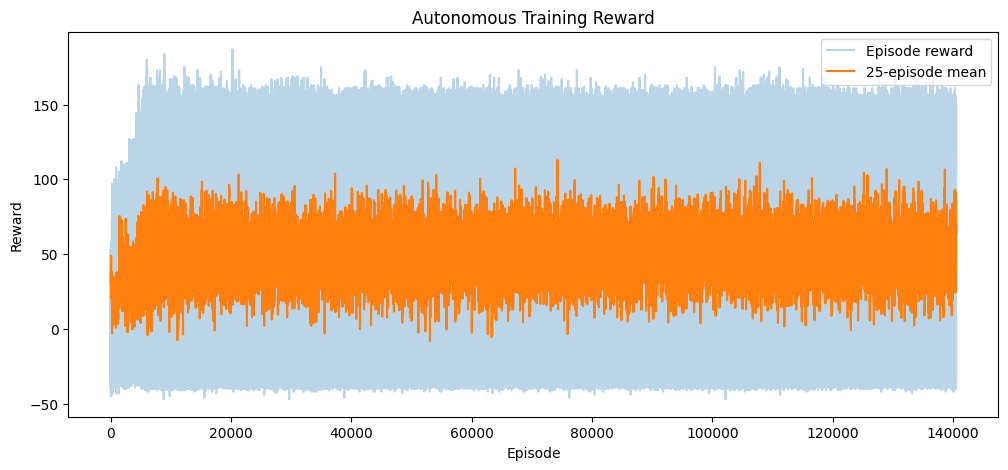

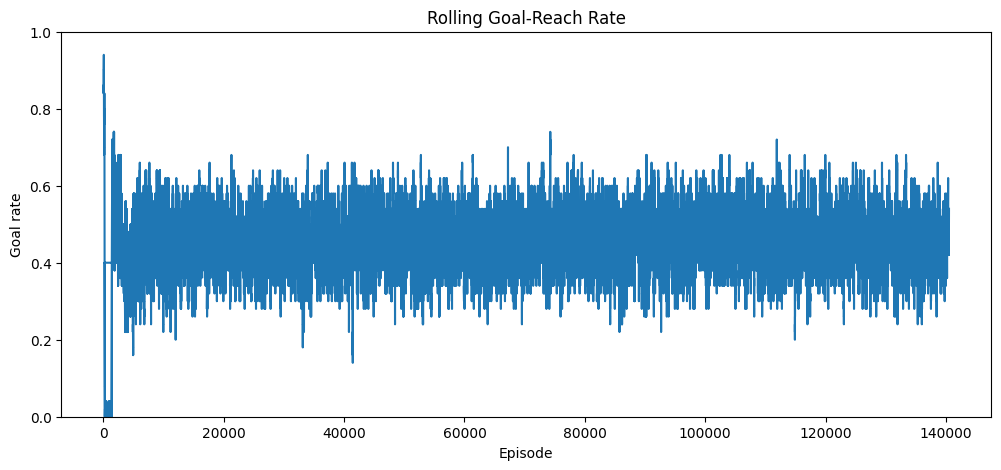

In [ ]:
def plot_training_history():
    if not os.path.exists(HISTORY_PATH):
        print("No history yet.")
        return
    df=pd.read_csv(HISTORY_PATH)

    plt.figure(figsize=(12,5))
    plt.plot(df["episode"],df["episode_reward"],alpha=0.30,label="Episode reward")
    if len(df)>=25:
        plt.plot(df["episode"],df["episode_reward"].rolling(25).mean(),label="25-episode mean")
    plt.xlabel("Episode"); plt.ylabel("Reward"); plt.title("Autonomous Training Reward")
    plt.legend(); plt.show()

    plt.figure(figsize=(12,5))
    plt.plot(df["episode"],df["goal_reached"].rolling(50).mean())
    plt.ylim(0,1)
    plt.xlabel("Episode"); plt.ylabel("Goal rate"); plt.title("Rolling Goal-Reach Rate")
    plt.show()

plot_training_history()


## 13. Streamlit dashboard

The browser dashboard controls the autonomous worker through a persistent command file. It automatically refreshes every 3 seconds, so training status, episode count, live events, training curves, and attack effectiveness update without manual page refreshes.


In [ ]:
STREAMLIT_APP = r'''
import os, json, time
import pandas as pd
import streamlit as st
import networkx as nx
import matplotlib.pyplot as plt

CHECKPOINT_DIR=os.environ.get("OFFENSIVE_AI_CHECKPOINT_DIR","/content/drive/MyDrive/offensive_ai_v5_checkpoints")
HISTORY_PATH=os.path.join(CHECKPOINT_DIR,"training_history.csv")
STATUS_PATH=os.path.join(CHECKPOINT_DIR,"training_status.json")
LIVE_EVENT_PATH=os.path.join(CHECKPOINT_DIR,"live_event.json")
ATTACK_STATS_PATH=os.path.join(CHECKPOINT_DIR,"attack_effectiveness.json")
CONTROL_PATH=os.path.join(CHECKPOINT_DIR,"training_control.json")

st.set_page_config(page_title="Offensive AI Adaptive Simulator",page_icon="shield",layout="wide")
st.title("Offensive AI Adaptive Simulator")
st.caption("Autonomous synthetic reinforcement-learning dashboard")

def load_json(path):
    try:
        with open(path,"r") as f: return json.load(f)
    except Exception: return {}

def write_command(command):
    payload={"command":command,"timestamp":time.time()}
    tmp=CONTROL_PATH+".tmp"
    with open(tmp,"w") as f: json.dump(payload,f,indent=2)
    os.replace(tmp,CONTROL_PATH)

def heartbeat_age(status):
    hb=status.get("last_heartbeat")
    if hb is None: return None
    try: return max(0.0,time.time()-float(hb))
    except Exception: return None

def resolve_training_state(status):
    explicit=status.get("state")
    age=heartbeat_age(status)
    if explicit=="running" and age is not None and age<=30: return "running","RUNNING",age
    if explicit=="stopped": return "complete","STOPPED",age
    if explicit=="completed": return "complete","COMPLETED",age
    if explicit=="error": return "error","ERROR",age
    if explicit=="running": return "error","STALE / NOT RESPONDING",age
    return "complete","IDLE",age

status=load_json(STATUS_PATH)
live=load_json(LIVE_EVENT_PATH)
attack_stats=load_json(ATTACK_STATS_PATH)
history=pd.read_csv(HISTORY_PATH) if os.path.exists(HISTORY_PATH) else pd.DataFrame()
status_state,status_label,heartbeat=resolve_training_state(status)

st.subheader("Autonomous Training Control")
b1,b2,b3=st.columns([1,1,2])
with b1:
    if st.button("START TRAINING",type="primary",use_container_width=True):
        write_command("start")
        st.rerun()
with b2:
    if st.button("STOP TRAINING",use_container_width=True):
        write_command("stop")
        st.rerun()
with b3:
    command=load_json(CONTROL_PATH).get("command","idle")
    st.write(f"**Command:** `{command.upper()}`")

status=load_json(STATUS_PATH)
status_state,status_label,heartbeat=resolve_training_state(status)
status_message={"running":"Autonomous training is actively running","complete":"Trainer is stopped or completed","error":"Trainer is not responding"}.get(status_state,"Waiting for START")
with st.status(status_message,state=status_state,expanded=True):
    s1,s2,s3,s4=st.columns(4)
    s1.metric("Process",status_label)
    s1.caption(status.get("message",""))
    s2.metric("Episode",f"{int(status.get('episode',live.get('episode',0))):,}")
    s3.metric("Stage",f"{int(status.get('stage_index',0))+1} / 8")
    s4.metric("Mastery",str(int(status.get('mastery_count',0))))
    st.write("**Current stage:**",status.get("current_stage",live.get("stage_name","Waiting")))
    if heartbeat is not None:
        st.write("**Last heartbeat:**",f"{heartbeat:.1f} seconds ago" if heartbeat<60 else f"{heartbeat/60:.1f} minutes ago")
    if status.get("error"): st.error(f"{status.get('error_type','Error')}: {status.get('error')}")

episode=int(status.get("episode",live.get("episode",0)))
stage=int(status.get("stage_index",0))+1
evaluation=status.get("last_eval",{})
goal_rate=float(evaluation.get("goal_rate",0)); reward=float(evaluation.get("mean_reward",0)); detection=float(evaluation.get("detection_rate",0))
c1,c2,c3,c4=st.columns(4)
c1.metric("Episode",f"{episode:,}"); c2.metric("Curriculum Stage",str(stage)); c3.metric("Goal Reach",f"{goal_rate:.1%}"); c4.metric("Mean Reward",f"{reward:.2f}")
st.divider()
left,right=st.columns(2)
with left:
    st.subheader("Training")
    st.write("**Current stage:**",status.get("current_stage",live.get("stage_name","Waiting")))
    st.write("**Device:**",live.get("device",status.get("device","unknown")))
    st.write("**Epsilon:**",f"{float(live.get('epsilon',0)):.3f}")
    st.write("**Detection rate:**",f"{detection:.1%}")
with right:
    st.subheader("Latest Synthetic Event")
    st.write("**Action:**",live.get("last_action","Waiting")); st.write("**Node:**",live.get("last_node","Waiting")); st.write("**Target:**",live.get("last_target","—"))
    st.write("**Success:**",live.get("last_success",False)); st.write("**Detected:**",live.get("last_detected",False))
    st.write("**Detection level:**",f"{float(live.get('detection_level',0)):.2f}"); st.write("**Alert level:**",f"{float(live.get('alert_level',0)):.2f}")

if not history.empty:
    st.divider(); st.subheader("Training Performance")
    a,b=st.columns(2)
    with a:
        chart=history[["episode","episode_reward"]].copy(); chart["rolling_reward"]=chart["episode_reward"].rolling(25).mean(); st.line_chart(chart.set_index("episode")[["episode_reward","rolling_reward"]])
    with b:
        chart=history[["episode","goal_reached"]].copy(); chart["rolling_goal_rate"]=chart["goal_reached"].rolling(50).mean(); st.line_chart(chart.set_index("episode")[["rolling_goal_rate"]])
    st.subheader("Curriculum Progress")
    st.dataframe(history.groupby(["stage","stage_name"]).size().reset_index(name="episodes"),use_container_width=True,hide_index=True)

st.divider(); st.subheader("Attack Effectiveness Analysis")
if attack_stats:
    rows=[]
    for name,stats in attack_stats.items():
        attempts=int(stats.get("attempts",0)); successes=int(stats.get("successes",0)); detections=int(stats.get("detections",0)); total=float(stats.get("total_reward",0)); goals=int(stats.get("goal_contributions",0))
        sr=successes/attempts if attempts else 0; dr=detections/attempts if attempts else 0; mr=total/attempts if attempts else 0
        score=100*(0.50*sr+0.30*max(0,min(1,(mr+2)/10))+0.20*(1-dr)) if attempts else 0
        cls="Highly Effective" if score>=80 else "Effective" if score>=65 else "Moderately Effective" if score>=45 else "Low Effectiveness" if attempts else "No Data"
        rows.append({"Attack":name,"Attempts":attempts,"Success Rate":sr,"Detection Rate":dr,"Mean Reward":mr,"Goal Contributions":goals,"Effectiveness Score":score,"Classification":cls})
    df=pd.DataFrame(rows).sort_values("Effectiveness Score",ascending=False)
    if df["Attempts"].sum()>0:
        top=df.iloc[0]; st.metric("Most Effective Attack",top["Attack"],f"{top['Effectiveness Score']:.1f}/100 · {top['Classification']}")
    else: st.info("Training has not produced attack-statistics data yet.")
    st.dataframe(df,use_container_width=True,hide_index=True)
else: st.info("Attack statistics will appear after training begins.")

st.divider(); st.subheader("Synthetic Enterprise Network")
G=nx.Graph(); G.add_edges_from([("john","admin"),("alice","admin"),("raj","admin"),("sara","admin"),("analyst","domain_controller"),("admin","database"),("database","domain_controller")])
pos=nx.spring_layout(G,seed=42); fig,ax=plt.subplots(figsize=(10,5)); nx.draw_networkx_edges(G,pos,ax=ax,alpha=0.45); nx.draw_networkx_nodes(G,pos,ax=ax,node_size=1500); nx.draw_networkx_labels(G,pos,ax=ax,font_size=9)
for node,size in [(live.get("last_node"),1900),(live.get("last_target"),1800)]:
    if node in G.nodes: nx.draw_networkx_nodes(G,pos,nodelist=[node],ax=ax,node_size=size)
ax.set_axis_off(); st.pyplot(fig,clear_figure=True)

st.subheader("Recent Training Episodes")
if not history.empty: st.dataframe(history.tail(25).iloc[::-1],use_container_width=True,hide_index=True)
st.caption("Synthetic simulation only. No external systems are contacted.")

# Automatic dashboard refresh. Training files are re-read every cycle.
time.sleep(3)
st.rerun()
'''


## 14. Launch Streamlit + ngrok

Run this after the autonomous worker has started. Use the dashboard START button to begin training and STOP to checkpoint and stop it.


In [ ]:
import subprocess, sys, time, os, getpass
from pyngrok import ngrok

STREAMLIT_APP_PATH = os.path.join(
    CHECKPOINT_DIR, "streamlit_dashboard.py"
)

with open(STREAMLIT_APP_PATH, "w", encoding="utf-8") as f:
    f.write(STREAMLIT_APP.lstrip())

os.environ["OFFENSIVE_AI_CHECKPOINT_DIR"] = CHECKPOINT_DIR

# Start/restart Streamlit only. The trainer is a separate background worker.
subprocess.run(
    ["pkill", "-f", "streamlit_dashboard.py"],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)
time.sleep(2)

ngrok_token = os.environ.get("NGROK_AUTH_TOKEN")
if not ngrok_token:
    ngrok_token = getpass.getpass("Enter ngrok auth token: ").strip()

if not ngrok_token:
    raise ValueError("ngrok auth token is required.")

ngrok.set_auth_token(ngrok_token)

log_path = os.path.join(CHECKPOINT_DIR, "streamlit.log")
streamlit_log = open(log_path, "a")

streamlit_process = subprocess.Popen(
    [
        sys.executable, "-m", "streamlit", "run",
        STREAMLIT_APP_PATH,
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true",
        "--browser.gatherUsageStats", "false",
    ],
    stdout=streamlit_log,
    stderr=subprocess.STDOUT,
)

time.sleep(5)

# Reuse a tunnel already attached to this local ngrok agent.
try:
    tunnels = ngrok.get_tunnels()
except Exception:
    tunnels = []

if tunnels:
    public_url = tunnels[0].public_url
    print("Reusing existing local ngrok tunnel.")
    print("STREAMLIT DASHBOARD:")
    print(public_url)
else:
    # Try a normal tunnel first. If the account has the same fixed endpoint
    # online elsewhere, try pooling so this runtime can share it instead of
    # crashing the notebook with ERR_NGROK_334.
    try:
        tunnel = ngrok.connect(8501, "http")
        public_url = tunnel.public_url
        print("STREAMLIT DASHBOARD:")
        print(public_url)
    except Exception as first_error:
        print("Normal ngrok tunnel could not be created.")
        print("Attempting pooled endpoint...")
        try:
            tunnel = ngrok.connect(
                8501,
                "http",
                pooling_enabled=True
            )
            public_url = tunnel.public_url
            print("STREAMLIT DASHBOARD:")
            print(public_url)
        except Exception as second_error:
            print()
            print("NGROK ENDPOINT IS ALREADY ONLINE.")
            print("The Streamlit server is still running locally on port 8501.")
            print()
            print("First error:", first_error)
            print("Second error:", second_error)
            print()
            print(
                "If you already have an online fixed ngrok endpoint, "
                "open that existing URL."
            )
            public_url = None

print()
print("Training and Streamlit are independent processes.")
print("The autonomous worker waits for START and responds to STOP.")
print("The dashboard refreshes automatically every 3 seconds.")


Resumed from episode 140475 stage 8
Episode 140500 | Stage 8/8 | Goal 50.0% | Reward 53.80 | Detection 62.6% | Epsilon 0.050
Episode 140550 | Stage 8/8 | Goal 36.7% | Reward 42.50 | Detection 59.7% | Epsilon 0.050
Episode 140600 | Stage 8/8 | Goal 43.3% | Reward 48.13 | Detection 65.9% | Epsilon 0.050
Episode 140650 | Stage 8/8 | Goal 50.0% | Reward 56.90 | Detection 60.6% | Epsilon 0.050
Episode 140700 | Stage 8/8 | Goal 43.3% | Reward 49.77 | Detection 64.9% | Epsilon 0.050
Episode 140750 | Stage 8/8 | Goal 43.3% | Reward 49.63 | Detection 65.0% | Epsilon 0.050
Episode 140800 | Stage 8/8 | Goal 36.7% | Reward 38.20 | Detection 67.4% | Epsilon 0.050
Episode 140850 | Stage 8/8 | Goal 50.0% | Reward 56.50 | Detection 57.9% | Epsilon 0.050
Episode 140900 | Stage 8/8 | Goal 50.0% | Reward 51.33 | Detection 69.8% | Epsilon 0.050
Episode 140950 | Stage 8/8 | Goal 40.0% | Reward 33.97 | Detection 62.4% | Epsilon 0.050
Episode 141000 | Stage 8/8 | Goal 53.3% | Reward 56.60 | Detection 59.1% |

## 15. Final evaluation


In [ ]:
# ============================================================
# FINAL EVALUATION - ALL CURRICULUM STAGES
# ============================================================

import os
import pandas as pd

def evaluate_all_stages(agent, episodes=100):
    rows = []

    for i, scenario in enumerate(CURRICULUM, start=1):
        print(
            f"Evaluating Stage {i}/{len(CURRICULUM)}: "
            f"{scenario['name']}..."
        )

        metrics = evaluate_agent(
            agent,
            scenario,
            episodes=episodes,
            seed_offset=500000 + i * 10000
        )

        rows.append({
            "Stage": i,
            "Scenario": scenario["name"],
            "Goal Rate": metrics["goal_rate"],
            "Mean Reward": metrics["mean_reward"],
            "Detection Rate": metrics["detection_rate"],
            "Mean Episode Length": metrics["mean_episode_length"]
        })

    return pd.DataFrame(rows)


# ------------------------------------------------------------
# Load the latest saved checkpoint
# ------------------------------------------------------------

probe = SyntheticEnterpriseEnv(
    CURRICULUM[0],
    SEED
)

evaluation_agent = DoubleDQNAgent(
    probe.state_size,
    probe.action_size
)

if not os.path.exists(LATEST_PATH):
    raise FileNotFoundError(
        f"Latest checkpoint not found:\n{LATEST_PATH}"
    )

evaluation_state = load_checkpoint(
    evaluation_agent,
    LATEST_PATH
)

print(
    f"Loaded checkpoint from episode "
    f"{evaluation_state.get('episode', '?')} "
    f"stage {evaluation_state.get('stage_index', 0) + 1}"
)

# ------------------------------------------------------------
# Evaluate every curriculum stage
# ------------------------------------------------------------

final_results = evaluate_all_stages(
    evaluation_agent,
    episodes=100
)

display(final_results)

# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

print("\nFinal Evaluation Summary")
print("=" * 60)

print(
    f"Average Goal Rate: "
    f"{final_results['Goal Rate'].mean():.1%}"
)

print(
    f"Average Mean Reward: "
    f"{final_results['Mean Reward'].mean():.2f}"
)

print(
    f"Average Detection Rate: "
    f"{final_results['Detection Rate'].mean():.1%}"
)

print(
    f"Average Episode Length: "
    f"{final_results['Mean Episode Length'].mean():.1f}"
)

Loaded checkpoint from episode 141400 stage 8
Evaluating Stage 1/8: Stage 1 — Basic Compromise...
Evaluating Stage 2/8: Stage 2 — Detection Awareness...
Evaluating Stage 3/8: Stage 3 — Privilege Escalation...
Episode 141450 | Stage 8/8 | Goal 46.7% | Reward 52.23 | Detection 60.7% | Epsilon 0.050
Evaluating Stage 4/8: Stage 4 — Lateral Movement...
Evaluating Stage 5/8: Stage 5 — High Detection...
Evaluating Stage 6/8: Stage 6 — Low Trust...
Episode 141500 | Stage 8/8 | Goal 50.0% | Reward 61.40 | Detection 65.8% | Epsilon 0.050
Evaluating Stage 7/8: Stage 7 — Stressed Users...
Evaluating Stage 8/8: Stage 8 — Full Adaptive Scenario...


,Stage,Scenario,Goal Rate,Mean Reward,Detection Rate,Mean Episode Length
0,1,Stage 1 — Basic Compromise,0.90,38.20,0.214713,4.10
1,2,Stage 2 — Detection Awareness,0.82,37.01,0.369508,3.56
2,3,Stage 3 — Privilege Escalation,0.00,20.75,0.558749,7.40
3,4,Stage 4 — Lateral Movement,0.64,53.15,0.526938,5.31
4,5,Stage 5 — High Detection,0.52,37.24,0.681028,5.09
5,6,Stage 6 — Low Trust,0.27,13.86,0.599716,6.08
6,7,Stage 7 — Stressed Users,0.50,60.66,0.559040,5.85
7,8,Stage 8 — Full Adaptive Scenario,0.48,51.86,0.632266,5.15



Final Evaluation Summary
Average Goal Rate: 51.6%
Average Mean Reward: 39.09
Average Detection Rate: 51.8%
Average Episode Length: 5.3


## 16. Research report export


In [ ]:
# ============================================================
# RESEARCH REPORT EXPORT
# ============================================================

import os
import json
from datetime import datetime, timezone

# ------------------------------------------------------------
# Load the latest saved training state
# ------------------------------------------------------------

if not os.path.exists(LATEST_PATH):
    raise FileNotFoundError(
        f"Latest checkpoint not found:\n{LATEST_PATH}"
    )

checkpoint = torch.load(
    LATEST_PATH,
    map_location=DEVICE,
    weights_only=False
)

saved_training_state = checkpoint["training_state"]

print(
    f"Loaded training state from episode "
    f"{saved_training_state.get('episode', '?')} "
    f"stage {saved_training_state.get('stage_index', 0) + 1}"
)

# ------------------------------------------------------------
# Build research report
# ------------------------------------------------------------

report = {
    "model": "Double DQN",
    "environment": "Synthetic Enterprise Adaptive Simulation",
    "device": str(DEVICE),

    "curriculum_stages": len(CURRICULUM),

    "total_episodes": int(
        saved_training_state.get("episode", 0)
    ),

    "final_stage": int(
        saved_training_state.get("stage_index", 0) + 1
    ),

    "best_goal_rate": float(
        saved_training_state.get("best_goal_rate", 0.0)
    ),

    "last_evaluation": saved_training_state.get(
        "last_eval", {}
    ),

    "synthetic_only": True,

    "real_password_dataset_used": False,

    "generated_at": datetime.now(
        timezone.utc
    ).isoformat()
}

# ------------------------------------------------------------
# Save report
# ------------------------------------------------------------

report_path = os.path.join(
    CHECKPOINT_DIR,
    "final_training_report.json"
)

with open(report_path, "w") as f:
    json.dump(
        report,
        f,
        indent=2,
        default=str
    )

print()
print(json.dumps(report, indent=2))
print()
print("Saved:", report_path)

Loaded training state from episode 141525 stage 8

{
  "model": "Double DQN",
  "environment": "Synthetic Enterprise Adaptive Simulation",
  "device": "cpu",
  "curriculum_stages": 8,
  "total_episodes": 141525,
  "final_stage": 8,
  "best_goal_rate": 0.9,
  "last_evaluation": {
    "goal_rate": 0.5,
    "mean_reward": 61.4,
    "detection_rate": 0.6583730158730159,
    "mean_episode_length": 5.5
  },
  "synthetic_only": true,
  "real_password_dataset_used": false,
  "generated_at": "2026-11-26T14:39:47.718223+00:00"
}

Saved: /content/drive/MyDrive/offensive_ai_v5_checkpoints/final_training_report.json


## 17. Interpretation

The model learns a policy rather than memorizing a textbook.

Its training loop is:

**state → masked action → synthetic outcome → reward → next state → replay → Double DQN update → evaluation → curriculum advancement → checkpoint**

The principal research metrics are goal-reach rate, mean reward, detection rate, mean episode length, training loss, epsilon, and performance across curriculum scenarios.

This notebook intentionally uses a synthetic environment. It does not contact external systems and does not perform real password cracking.


## V5.5 Live training status

The trainer now publishes a lifecycle state and heartbeat. The Streamlit dashboard displays RUNNING, COMPLETED, ERROR, or STALE / NOT RESPONDING and refreshes every 3 seconds. The trainer is started in a background thread so the dashboard can observe it concurrently in the same Colab runtime.


In [ ]:
# ============================================================
# COMPLETE RESEARCH DATA EXPORT - AUTO DISCOVERY VERSION
# ============================================================

import os
import json
import shutil
from datetime import datetime, timezone

print("=" * 70)
print("PREPARING COMPLETE RESEARCH DATA EXPORT")
print("=" * 70)

# ------------------------------------------------------------
# 1. Find the actual checkpoint directory
# ------------------------------------------------------------

print("\nSearching for training files...")

# First check environment variable used by Streamlit
possible_dirs = []

env_checkpoint = os.environ.get(
    "OFFENSIVE_AI_CHECKPOINT_DIR"
)

if env_checkpoint:
    possible_dirs.append(env_checkpoint)

# Known locations
possible_dirs.extend([
    "/content/drive/MyDrive/offensive_ai_v5_checkpoints",
    "/content/drive/MyDrive/offensive_ai_checkpoints",
    "/content/offensive_ai_v5_checkpoints",
    "/content/offensive_ai_checkpoints",
])

# Remove duplicates
possible_dirs = list(dict.fromkeys(possible_dirs))

EXPORT_SOURCE = None

# Check known locations first
for candidate in possible_dirs:

    if os.path.isdir(candidate):

        latest = os.path.join(
            candidate,
            "latest.pt"
        )

        history = os.path.join(
            candidate,
            "training_history.csv"
        )

        if os.path.exists(latest) or os.path.exists(history):

            EXPORT_SOURCE = candidate
            break

# ------------------------------------------------------------
# 2. If not found, search /content
# ------------------------------------------------------------

if EXPORT_SOURCE is None:

    print("Checkpoint directory not found at known locations.")
    print("Searching /content for training artifacts...")

    found_candidates = []

    for root, dirs, files in os.walk("/content"):

        # Ignore some huge/unhelpful directories
        dirs[:] = [
            d for d in dirs
            if d not in [
                ".cache",
                ".config",
                "node_modules",
                "__pycache__"
            ]
        ]

        interesting = {
            "latest.pt",
            "best.pt",
            "training_history.csv",
            "attack_effectiveness.json",
            "training_status.json"
        }

        if any(
            filename in files
            for filename in interesting
        ):

            found_candidates.append(root)

    if found_candidates:

        # Prefer directories containing latest.pt
        latest_candidates = [
            p for p in found_candidates
            if os.path.exists(
                os.path.join(p, "latest.pt")
            )
        ]

        if latest_candidates:
            EXPORT_SOURCE = latest_candidates[0]
        else:
            EXPORT_SOURCE = found_candidates[0]

# ------------------------------------------------------------
# 3. Fail only if absolutely nothing was found
# ------------------------------------------------------------

if EXPORT_SOURCE is None:

    print("\nNO TRAINING FILES FOUND.")
    print()
    print("Current /content directories:")

    try:
        for item in os.listdir("/content"):
            print("  ", item)
    except Exception:
        pass

    raise FileNotFoundError(
        "\nCould not locate latest.pt or training_history.csv "
        "anywhere under /content.\n\n"
        "This usually means the Google Drive containing the "
        "checkpoint has not been mounted in this notebook runtime."
    )

print()
print("=" * 70)
print("CHECKPOINT DIRECTORY FOUND")
print("=" * 70)
print(EXPORT_SOURCE)

# ------------------------------------------------------------
# 4. Create export directory
# ------------------------------------------------------------

timestamp = datetime.now().strftime(
    "%Y%m%d_%H%M%S"
)

EXPORT_DIR = os.path.join(
    EXPORT_SOURCE,
    f"research_export_{timestamp}"
)

os.makedirs(
    EXPORT_DIR,
    exist_ok=True
)

print()
print("Export directory:")
print(EXPORT_DIR)

# ------------------------------------------------------------
# 5. Copy all important research artifacts
# ------------------------------------------------------------

files_to_copy = [
    "latest.pt",
    "best.pt",
    "training_history.csv",
    "attack_effectiveness.json",
    "training_status.json",
    "live_event.json",
    "training_control.json",
    "final_training_report.json",
    "streamlit.log",
]

copied = []
missing = []

print()
print("=" * 70)
print("COPYING TRAINING DATA")
print("=" * 70)

for filename in files_to_copy:

    source = os.path.join(
        EXPORT_SOURCE,
        filename
    )

    destination = os.path.join(
        EXPORT_DIR,
        filename
    )

    if os.path.isfile(source):

        shutil.copy2(
            source,
            destination
        )

        copied.append(filename)

        print(f"[OK]   {filename}")

    else:

        missing.append(filename)

        print(f"[SKIP] {filename}")

# ------------------------------------------------------------
# 6. Read latest checkpoint
# ------------------------------------------------------------

latest_checkpoint = os.path.join(
    EXPORT_SOURCE,
    "latest.pt"
)

checkpoint_summary = {}

if os.path.isfile(latest_checkpoint):

    print()
    print("Reading latest checkpoint...")

    # torch should already exist in the notebook.
    checkpoint = torch.load(
        latest_checkpoint,
        map_location="cpu",
        weights_only=False
    )

    saved_state = checkpoint.get(
        "training_state",
        {}
    )

    checkpoint_summary = {

        "exported_at":
            datetime.now(
                timezone.utc
            ).isoformat(),

        "episode":
            int(
                saved_state.get(
                    "episode",
                    0
                )
            ),

        "stage_index":
            int(
                saved_state.get(
                    "stage_index",
                    0
                )
            ),

        "stage":
            int(
                saved_state.get(
                    "stage_index",
                    0
                ) + 1
            ),

        "stage_episode":
            int(
                saved_state.get(
                    "stage_episode",
                    0
                )
            ),

        "mastery_count":
            int(
                saved_state.get(
                    "mastery_count",
                    0
                )
            ),

        "best_goal_rate":
            float(
                saved_state.get(
                    "best_goal_rate",
                    0.0
                )
            ),

        "best_stage_goal_rate":
            float(
                saved_state.get(
                    "best_stage_goal_rate",
                    0.0
                )
            ),

        "last_evaluation":
            saved_state.get(
                "last_eval",
                {}
            ),

        "checkpoint_saved_at":
            checkpoint.get(
                "saved_at",
                None
            )
    }

    with open(
        os.path.join(
            EXPORT_DIR,
            "checkpoint_summary.json"
        ),
        "w"
    ) as f:

        json.dump(
            checkpoint_summary,
            f,
            indent=2,
            default=str
        )

    print(
        "[OK] checkpoint_summary.json"
    )

# ------------------------------------------------------------
# 7. Export final evaluation results
# ------------------------------------------------------------

if (
    "final_results" in globals()
    and hasattr(
        final_results,
        "to_csv"
    )
):

    final_results.to_csv(
        os.path.join(
            EXPORT_DIR,
            "final_evaluation_results.csv"
        ),
        index=False
    )

    print(
        "[OK] final_evaluation_results.csv"
    )

else:

    print(
        "[SKIP] final_evaluation_results.csv "
        "(final_results not available)"
    )

# ------------------------------------------------------------
# 8. Export attack effectiveness
# ------------------------------------------------------------

attack_stats_path = os.path.join(
    EXPORT_SOURCE,
    "attack_effectiveness.json"
)

if os.path.isfile(attack_stats_path):

    with open(
        attack_stats_path,
        "r"
    ) as f:

        attack_stats = json.load(f)

    with open(
        os.path.join(
            EXPORT_DIR,
            "attack_effectiveness_snapshot.json"
        ),
        "w"
    ) as f:

        json.dump(
            attack_stats,
            f,
            indent=2,
            default=str
        )

    print(
        "[OK] attack_effectiveness_snapshot.json"
    )

else:

    print(
        "[SKIP] attack_effectiveness_snapshot.json"
    )

# ------------------------------------------------------------
# 9. Create experiment summary
# ------------------------------------------------------------

experiment_summary = {

    "project":
        "Offensive AI Adaptive Password & Social Engineering Simulator",

    "research_title":
        "Adversary Emulation Coverage Against the Untested Technique Space",

    "model":
        "Curriculum-Trained Double DQN",

    "environment":
        "Synthetic Enterprise Adaptive Simulation",

    "synthetic_only":
        True,

    "export_time":
        datetime.now(
            timezone.utc
        ).isoformat(),

    "checkpoint_directory":
        EXPORT_SOURCE,

    "files_copied":
        copied,

    "files_missing":
        missing
}

if checkpoint_summary:

    experiment_summary.update({

        "training_episode":
            checkpoint_summary[
                "episode"
            ],

        "current_stage":
            checkpoint_summary[
                "stage"
            ],

        "stage_episode":
            checkpoint_summary[
                "stage_episode"
            ],

        "mastery_count":
            checkpoint_summary[
                "mastery_count"
            ],

        "best_goal_rate":
            checkpoint_summary[
                "best_goal_rate"
            ],

        "best_stage_goal_rate":
            checkpoint_summary[
                "best_stage_goal_rate"
            ]
    })

if "CURRICULUM" in globals():

    experiment_summary[
        "curriculum_stages"
    ] = len(CURRICULUM)

if "DEVICE" in globals():

    experiment_summary[
        "device"
    ] = str(DEVICE)

with open(
    os.path.join(
        EXPORT_DIR,
        "experiment_summary.json"
    ),
    "w"
) as f:

    json.dump(
        experiment_summary,
        f,
        indent=2,
        default=str
    )

print(
    "[OK] experiment_summary.json"
)

# ------------------------------------------------------------
# 10. Create ZIP
# ------------------------------------------------------------

zip_base = os.path.join(
    EXPORT_SOURCE,
    f"research_results_{timestamp}"
)

zip_path = shutil.make_archive(
    zip_base,
    "zip",
    EXPORT_DIR
)

# ------------------------------------------------------------
# 11. Final output
# ------------------------------------------------------------

print()
print("=" * 70)
print("EXPORT COMPLETE")
print("=" * 70)

print(
    f"Training directory:\n{EXPORT_SOURCE}"
)

print()
print(
    f"Files copied: {len(copied)}"
)

print(
    f"Files missing: {len(missing)}"
)

print(
    f"ZIP size: "
    f"{os.path.getsize(zip_path) / (1024**2):.2f} MB"
)

print()
print(
    f"ZIP archive:\n{zip_path}"
)

# ------------------------------------------------------------
# 12. Download ZIP in Colab
# ------------------------------------------------------------

try:

    from google.colab import files

    files.download(zip_path)

    print()
    print("Download started.")

except Exception as e:

    print()
    print(
        "Automatic Colab download unavailable."
    )

    print(
        f"ZIP location:\n{zip_path}"
    )

PREPARING COMPLETE RESEARCH DATA EXPORT

Searching for training files...

CHECKPOINT DIRECTORY FOUND
/content/drive/MyDrive/offensive_ai_v5_checkpoints

Export directory:
/content/drive/MyDrive/offensive_ai_v5_checkpoints/research_export_20261126_143948

COPYING TRAINING DATA
Episode 141550 | Stage 8/8 | Goal 43.3% | Reward 40.83 | Detection 66.0% | Epsilon 0.050
[OK]   latest.pt
[OK]   best.pt
[OK]   training_history.csv
[OK]   attack_effectiveness.json
[OK]   training_status.json
[OK]   live_event.json
[OK]   training_control.json
[OK]   final_training_report.json
[OK]   streamlit.log

Reading latest checkpoint...
[OK] checkpoint_summary.json
[OK] final_evaluation_results.csv
[OK] attack_effectiveness_snapshot.json
[OK] experiment_summary.json

EXPORT COMPLETE
Training directory:
/content/drive/MyDrive/offensive_ai_v5_checkpoints

Files copied: 9
Files missing: 0
ZIP size: 4.49 MB

ZIP archive:
/content/drive/MyDrive/offensive_ai_v5_checkpoints/research_results_20261126_143948.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Download started.
Episode 141600 | Stage 8/8 | Goal 36.7% | Reward 36.73 | Detection 65.3% | Epsilon 0.050
